In [25]:
library(ggplot2)
library(dplyr)
library(ggpubr)

Warning message:
“程辑包‘ggpubr’是用R版本4.1.3 来建造的”


In [9]:
RNA <- read.csv('/media/AnalysisTempDisk2/Wuyisha/RNA/AR/H5ad_files/RNA_ATAC_proportion_revise/scRNA_celltype_L2_prop.csv')
ATAC <- read.csv('/media/AnalysisTempDisk2/Wuyisha/RNA/AR/H5ad_files/RNA_ATAC_proportion_revise/scATAC_celltype_L2_prop.csv')

In [35]:
color_df <- read.csv('/media/AnalysisTempDisk2/Wuyisha/RNA/AR/H5ad_files/color_label/cell_type_L2_fibro_label.csv')

In [36]:
head(color_df)

,label,color
,<chr>,<chr>
1,Basal_Cells,#2fa7ab
2,Cilliated_Cells,#2c6997
3,Secretory_Cells,#1c6c74
4,Ionocytes,#4d76bb
5,Glandular_Cells,#4191bc
6,Fibroblasts,#aa855b


In [10]:
RNA$data <- 'scRNA-seq'
colnames(RNA)[colnames(RNA) == "relative_freq"] <- "relative_freq_scRNA"
ATAC$data <- 'scATAC-seq'
colnames(ATAC)[colnames(ATAC) == "relative_freq"] <- "relative_freq_scATAC"

In [15]:
head(RNA)

,PatientID,celltype_L2_manual_res.0.7,relative_freq_scRNA,Group,data,sample_celltype
,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>
1,HNM04,B_Cells,0.058944583,AR,scRNA-seq,HNM04_B_Cells
2,HNM05,B_Cells,0.004165595,AR,scRNA-seq,HNM05_B_Cells
3,HNM07,B_Cells,0.030640023,AR,scRNA-seq,HNM07_B_Cells
4,HNM09,B_Cells,0.028308892,NAR,scRNA-seq,HNM09_B_Cells
5,HNM10,B_Cells,0.002280150,NAR,scRNA-seq,HNM10_B_Cells
6,HNM14,B_Cells,0.015974441,AR,scRNA-seq,HNM14_B_Cells


In [52]:
unique(RNA$celltype_L2_manual_res.0.7)

[1] "B_Cells"           "Basal_Cells"       "CD4 T_Cells"      
 [4] "CD8 T_Cells"       "Cilliated_Cells"   "Endothelial_Cells"
 [7] "Fibroblasts"       "Glandular_Cells"   "Glia"             
[10] "Ionocytes"         "Mast_Cells"        "Myeloid_Cells"    
[13] "Myofibroblast"     "Plasma"            "Secretory_Cells"

In [53]:
unique(ATAC$celltype_L2_manual_res.0.7)

[1] "B_Cells"           "Basal_Cells"       "CD4 T_Cells"      
 [4] "CD8 T_Cells"       "Cilliated_Cells"   "Endothelial_Cells"
 [7] "Fibroblasts"       "Glandular_Cells"   "Ionocytes"        
[10] "Mast_Cells"        "Myeloid_Cells"     "Myofibroblast"    
[13] "Plasma"            "Secretory_Cells"

In [42]:
ATAC$celltype_L2_manual_res.0.7[ATAC$celltype_L2_manual_res.0.7 == "CD8 T_cells"] <- "CD8 T_Cells"
ATAC$celltype_L2_manual_res.0.7[ATAC$celltype_L2_manual_res.0.7 == "Ciliated_Cells"] <- "Cilliated_Cells"
ATAC$celltype_L2_manual_res.0.7[ATAC$celltype_L2_manual_res.0.7 == "Endothelial_cells"] <- "Endothelial_Cells"

In [43]:
head(ATAC)

,PatientID,celltype_L2_manual_res.0.7,relative_freq_scATAC,Group,data,sample_celltype
,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>
1,HNM04,B_Cells,0.04821458,AR,scATAC-seq,HNM04_B_Cells
2,HNM04,Basal_Cells,0.23399704,AR,scATAC-seq,HNM04_Basal_Cells
3,HNM04,CD4 T_Cells,0.01497449,AR,scATAC-seq,HNM04_CD4 T_Cells
4,HNM04,CD8 T_Cells,0.16406121,AR,scATAC-seq,HNM04_CD8 T_cells
5,HNM04,Cilliated_Cells,0.03291098,AR,scATAC-seq,HNM04_Ciliated_Cells
6,HNM04,Endothelial_Cells,0.11584663,AR,scATAC-seq,HNM04_Endothelial_cells


In [56]:
RNA <- RNA %>%
  mutate(sample_celltype = paste(PatientID, celltype_L2_manual_res.0.7, sep = "_"))

ATAC <- ATAC %>%
  mutate(sample_celltype = paste(PatientID, celltype_L2_manual_res.0.7, sep = "_"))

In [57]:
merged <- inner_join(RNA, ATAC, by = c("PatientID", "celltype_L2_manual_res.0.7",'Group','sample_celltype'))

In [58]:
table(merged$`celltype_L2_manual_res.0.7`)


          B_Cells       Basal_Cells       CD4 T_Cells       CD8 T_Cells 
               24                24                24                24 
  Cilliated_Cells Endothelial_Cells       Fibroblasts   Glandular_Cells 
               24                24                24                24 
        Ionocytes        Mast_Cells     Myeloid_Cells     Myofibroblast 
               24                24                24                24 
           Plasma   Secretory_Cells 
               24                24 

In [59]:
head(merged)

,PatientID,celltype_L2_manual_res.0.7,relative_freq_scRNA,Group,data.x,sample_celltype,relative_freq_scATAC,data.y
,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<chr>
1,HNM04,B_Cells,0.058944583,AR,scRNA-seq,HNM04_B_Cells,0.048214580,scATAC-seq
2,HNM05,B_Cells,0.004165595,AR,scRNA-seq,HNM05_B_Cells,0.005324117,scATAC-seq
3,HNM07,B_Cells,0.030640023,AR,scRNA-seq,HNM07_B_Cells,0.021849395,scATAC-seq
4,HNM09,B_Cells,0.028308892,NAR,scRNA-seq,HNM09_B_Cells,0.034163503,scATAC-seq
5,HNM10,B_Cells,0.002280150,NAR,scRNA-seq,HNM10_B_Cells,0.001471738,scATAC-seq
6,HNM14,B_Cells,0.015974441,AR,scRNA-seq,HNM14_B_Cells,0.005248092,scATAC-seq



	Pearson's product-moment correlation

data:  merged_B_Cells$relative_freq_scRNA and merged_B_Cells$relative_freq_scATAC
t = 2.845, df = 22, p-value = 0.009419
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 0.1456956 0.7624907
sample estimates:
      cor 
0.5186119 


	Spearman's rank correlation rho

data:  merged_B_Cells$relative_freq_scRNA and merged_B_Cells$relative_freq_scATAC
S = 602, p-value = 6.004e-05
alternative hypothesis: true rho is not equal to 0
sample estimates:
      rho 
0.7382609 



`geom_smooth()` using formula = 'y ~ x'


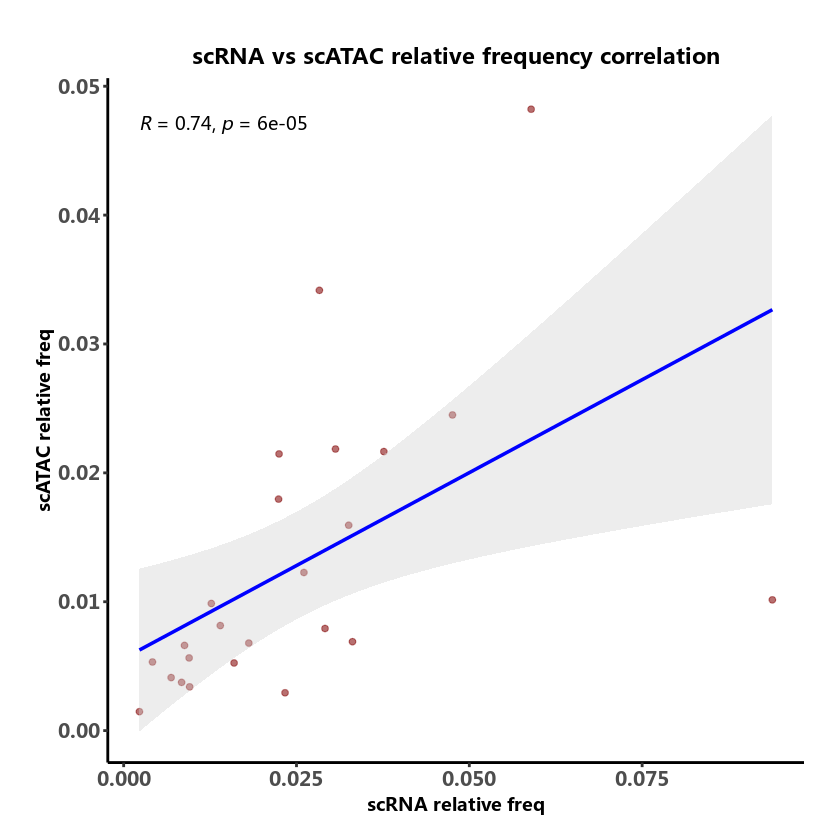

In [60]:
merged_B_Cells <- merged %>%
  filter(celltype_L2_manual_res.0.7 == "B_Cells")

# Pearson 相关性
cor_test <- cor.test(merged_B_Cells$relative_freq_scRNA, merged_B_Cells$relative_freq_scATAC, method = "pearson")
print(cor_test)

# Spearman 相关性（更稳健）
cor_test_spear <- cor.test(merged_B_Cells$relative_freq_scRNA, merged_B_Cells$relative_freq_scATAC, method = "spearman")
print(cor_test_spear)



ggplot(merged_B_Cells, aes(x = relative_freq_scRNA, y = relative_freq_scATAC)) +
  geom_point(color = "#993333", alpha = 0.7) +
  geom_smooth(method = "lm", se = TRUE, color = "blue",fill = "lightgray") +
  labs(title = "scRNA vs scATAC relative frequency correlation",
       x = "scRNA relative freq",
       y = "scATAC relative freq") +
  stat_cor(method = "spearman") + #添加相关系数和显著P值
  # theme_minimal()+
  theme(
  plot.title = element_text(hjust = 0.5),
  panel.background = element_blank(), #设置面板背景为白色
  panel.grid = element_blank(), #去除网格
  plot.margin = unit(c(2, 1.5, 1, 1.5), 'lines'),
  text = element_text(face = 'bold'),
  axis.text = element_text(size = 12, face = 'bold'),
  axis.line = element_line(size = .8),
  axis.ticks = element_line(size = .8)
  )

In [61]:
library(ggplot2)
library(ggpubr)

# 假设 color 数据框如下（已加载）
# color_df <- read.csv("your_color_file.csv")  # 或你已经有了

# 获取所有细胞类型
cell_types <- unique(merged$celltype_L2_manual_res.0.7)

# 遍历每个细胞类型
for (ct in cell_types) {
  # 过滤数据
  sub_data <- merged %>% filter(celltype_L2_manual_res.0.7 == ct)
  
  # 跳过数据点太少的类型
  if (nrow(sub_data) < 3) next
  
  # 获取对应颜色
  color_hex <- color_df$color[match(ct, color_df$label)]
  if (is.na(color_hex)) color_hex <- "gray40"  # 默认颜色
  
  # 计算相关性
  pearson_cor <- cor.test(sub_data$relative_freq_scRNA, sub_data$relative_freq_scATAC, method = "pearson")
  spearman_cor <- cor.test(sub_data$relative_freq_scRNA, sub_data$relative_freq_scATAC, method = "spearman")
  
  # 打印结果
  cat(sprintf("\n=== %s ===\n", ct))
  cat(sprintf("Pearson: r = %.3f, p = %.3e\n", pearson_cor$estimate, pearson_cor$p.value))
  cat(sprintf("Spearman: rho = %.3f, p = %.3e\n", spearman_cor$estimate, spearman_cor$p.value))
  
  # 绘图
  p <- ggplot(sub_data, aes(x = relative_freq_scRNA, y = relative_freq_scATAC)) +
    geom_point(color = color_hex, alpha = 0.7) +
    geom_smooth(method = "lm", se = TRUE, color = "blue", fill = "lightgray") +
    labs(
      title = paste("scRNA vs scATAC:", ct),
      x = "scRNA relative freq",
      y = "scATAC relative freq"
    ) +
    stat_cor(method = "spearman") +
    theme(
      plot.title = element_text(hjust = 0.5, face = "bold"),
      panel.background = element_blank(),
      panel.grid = element_blank(),
      plot.margin = unit(c(2, 1.5, 1, 1.5), 'lines'),
      text = element_text(face = 'bold'),
      axis.text = element_text(size = 12, face = 'bold'),
      axis.line = element_line(size = .8),
      axis.ticks = element_line(size = .8)
    )
  
  # 保存图像（可选）
  ggsave(filename = paste0("correlation_", gsub("[^[:alnum:]]", "_", ct), ".pdf"), plot = p, width = 6, height = 5)
}


=== B_Cells ===
Pearson: r = 0.519, p = 9.419e-03
Spearman: rho = 0.738, p = 6.004e-05


`geom_smooth()` using formula = 'y ~ x'



=== Basal_Cells ===
Pearson: r = 0.776, p = 8.177e-06
Spearman: rho = 0.791, p = 6.755e-06


`geom_smooth()` using formula = 'y ~ x'



=== CD4 T_Cells ===
Pearson: r = 0.618, p = 1.279e-03
Spearman: rho = 0.704, p = 1.821e-04


...

`geom_smooth()` using formula = 'y ~ x'



=== Plasma ===
Pearson: r = 0.774, p = 9.173e-06
Spearman: rho = 0.816, p = 2.642e-06


`geom_smooth()` using formula = 'y ~ x'



=== Secretory_Cells ===
Pearson: r = -0.079, p = 7.151e-01
Spearman: rho = 0.237, p = 2.646e-01


`geom_smooth()` using formula = 'y ~ x'


In [63]:
library(ggplot2)
library(ggpubr)
library(gridExtra)   # 一次性拼图
# 如果想按行/列排版，也可以用 patchwork::wrap_plots()

## 1. 准备颜色（你已经有了 color_df）
cell_types <- unique(merged$celltype_L2_manual_res.0.7)
plot_list <- list()

## 2. 画图并收集到列表
for (ct in cell_types) {
  sub_data <- merged %>% filter(celltype_L2_manual_res.0.7 == ct)
  if (nrow(sub_data) < 3) next
  
  color_hex <- color_df$color[match(ct, color_df$label)]
  if (is.na(color_hex)) color_hex <- "gray40"
  
  p <- ggplot(sub_data, aes(x = relative_freq_scRNA, y = relative_freq_scATAC)) +
    geom_point(color = color_hex, alpha = 0.7) +
    geom_smooth(method = "lm", se = TRUE, color = "blue", fill = "lightgray") +
    labs(title = ct,
         x = "scRNA relative freq",
         y = "scATAC relative freq") +
    stat_cor(method = "spearman") +
    theme_bw(base_size = 14) +
    theme( plot.title = element_text(hjust = 0.5, face = "bold"),
      panel.background = element_blank(),
      panel.grid = element_blank(),
      plot.margin = unit(c(2, 1.5, 1, 1.5), 'lines'),
      text = element_text(face = 'bold'),
      axis.text = element_text(size = 12, face = 'bold'),
      axis.line = element_line(size = .8),
      axis.ticks = element_line(size = .8))
  
  plot_list[[ct]] <- p
}

## 3. 拼图并导出
# 每行 3 列，自动换行；adjust 行列数可按需要改
pdf("all_celltype_correlations.pdf", width = 15, height = 5 * ceiling(length(plot_list) / 3))
grid.arrange(grobs = plot_list, ncol = 3)
dev.off()

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


png 
  2